In [5]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns


In [6]:
df=pd.read_csv('tested.csv',usecols=['Age','Fare','Survived'])

In [7]:
df

,Survived,Age,Fare
0,0,34.5,7.8292
1,1,47.0,7.0000
2,0,62.0,9.6875
3,0,27.0,8.6625
4,1,22.0,12.2875
...,...,...,...
413,0,NaN,8.0500
414,1,39.0,108.9000
415,0,38.5,7.2500
416,0,NaN,8.0500


In [4]:
df.head()

,Survived,Age,Fare
0,0,34.5,7.8292
1,1,47.0,7.0000
2,0,62.0,9.6875
3,0,27.0,8.6625
4,1,22.0,12.2875


In [8]:
df.isnull().mean()*100

Survived     0.000000
Age         20.574163
Fare         0.239234
dtype: float64

In [9]:
X=df.drop(columns=['Survived'])
y=df['Survived']

In [10]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=2)

In [11]:
X_train['Age_imputed']=X_train['Age']
X_test['Age_imputed']=X_test['Age']


In [12]:
X_test.head()

,Age,Fare,Age_imputed
146,NaN,51.8625,NaN
223,21.0,7.7958,21.0
193,61.0,12.3500,61.0
305,64.0,26.5500,64.0
188,NaN,69.5500,NaN


In [14]:
X_test.tail()

,Age,Fare,Age_imputed
348,24.0,13.5000,24.0
30,50.0,26.0000,50.0
174,40.0,31.3875,40.0
68,31.0,28.5375,31.0
204,25.0,10.5000,25.0


In [13]:
X_train['Age_imputed'][X_train['Age_imputed'].isnull()]=X_train['Age'].dropna().sample(X_train['Age'].isnull().sum()).values
X_test['Age_imputed'][X_test['Age_imputed'].isnull()]=X_test['Age'].dropna().sample(X_test['Age'].isnull().sum()).values


C:\Users\Debjani Mukherjee\AppData\Local\Temp\ipykernel_13484\2623973072.py:1: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  X_train['Age_imputed'][X_train['Age_imputed'].isnull()]=X_train['Age'].dropna().sample(X_train['Age'].isnull().sum()

In [15]:
X_train['Age'].isnull().sum()

72

In [17]:
X_train

,Age,Fare,Age_imputed
280,23.0,8.6625,23.0
284,2.0,20.2125,2.0
40,39.0,13.4167,39.0
17,21.0,7.2250,21.0
362,31.0,21.0000,31.0
...,...,...,...
299,29.0,7.8542,29.0
22,NaN,31.6833,32.0
72,29.0,7.9250,29.0
15,24.0,27.7208,24.0


C:\Users\Debjani Mukherjee\AppData\Local\Temp\ipykernel_13484\629994495.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(X_train['Age'],label='Original',hist=False)
C:\Users\Debjani Mukherjee\AppData\Local\Temp\ipykernel_13484\629994495.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

 

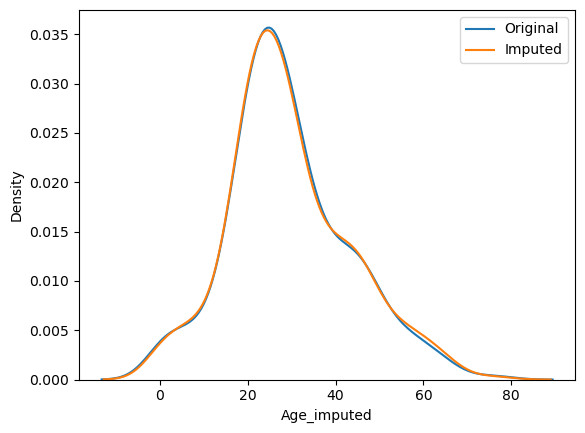

In [19]:
sns.distplot(X_train['Age'],label='Original',hist=False)
sns.distplot(X_train['Age_imputed'],label='Imputed',hist=False)
plt.legend()
plt.show()

In [20]:
print('Original variable variance:',X_train['Age'].var())
print('Variance after random imputation:',X_train['Age_imputed'].var())

Original variable variance: 184.7040299669505
Variance after random imputation: 190.0203505970043


In [21]:
X_train[['Fare','Age','Age_imputed']].cov()

,Fare,Age,Age_imputed
Fare,2333.007047,216.034928,166.109401
Age,216.034928,184.704030,184.704030
Age_imputed,166.109401,184.704030,190.020351


<Axes: >

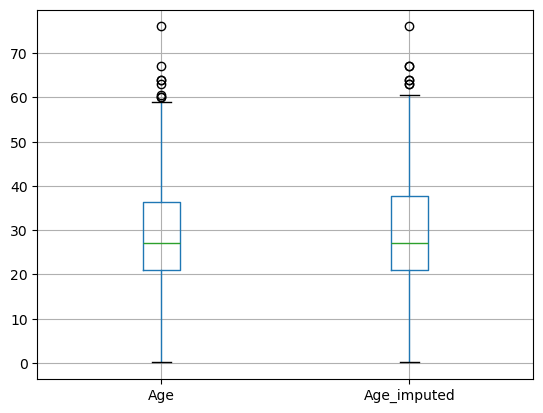

In [22]:
X_train[['Age','Age_imputed']].boxplot()


In [23]:
sampled_value=X_train['Age'].dropna().sample(1,random_state=int(observation['Fare']))

NameError: name 'observation' is not defined

In [24]:
data=pd.read_csv('train.csv',usecols=['GarageQual','FireplaceQu','SalePrice'])

In [25]:
data.head()

,FireplaceQu,GarageQual,SalePrice
0,NaN,TA,208500
1,TA,TA,181500
2,TA,TA,223500
3,Gd,TA,140000
4,TA,TA,250000


In [26]:
data.isnull().mean()*100

FireplaceQu    47.260274
GarageQual      5.547945
SalePrice       0.000000
dtype: float64

In [27]:
X=data
y=data['SalePrice']

In [28]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=2)


In [29]:
X_train['GarageQual_imputed']=X_train['GarageQual']
X_test['GarageQual_imputed']=X_test['GarageQual']

X_train['FireplaceQu_imputed']=X_train['FireplaceQu']
X_test['FireplaceQu_imputed']=X_test['FireplaceQu']



In [30]:
X_train.sample(5)

,FireplaceQu,GarageQual,SalePrice,GarageQual_imputed,FireplaceQu_imputed
1302,TA,TA,290000,TA,TA
712,Gd,TA,189000,TA,Gd
90,NaN,TA,109900,TA,NaN
784,Gd,NaN,128000,NaN,Gd
976,NaN,NaN,85500,NaN,NaN


In [31]:
X_train['GarageQual_imputed'][X_train['GarageQual_imputed'].isnull()]=X_train['GarageQual'].dropna().sample(X_train['GarageQual'].isnull().sum()).values
X_test['GarageQual_imputed'][X_test['GarageQual_imputed'].isnull()]=X_test['GarageQual'].dropna().sample(X_test['GarageQual'].isnull().sum()).values

X_train['FireplaceQu_imputed'][X_train['FireplaceQu_imputed'].isnull()]=X_train['FireplaceQu'].dropna().sample(X_train['FireplaceQu'].isnull().sum()).values
X_test['FireplaceQu_imputed'][X_test['FireplaceQu_imputed'].isnull()]=X_test['FireplaceQu'].dropna().sample(X_test['FireplaceQu'].isnull().sum()).values


C:\Users\Debjani Mukherjee\AppData\Local\Temp\ipykernel_13484\3420236241.py:1: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  X_train['GarageQual_imputed'][X_train['GarageQual_imputed'].isnull()]=X_train['GarageQual'].dropna().sample(X_train[

In [35]:
temp=pd.concat(
    [
        X_train['GarageQual'].value_counts()/len(X_train['GarageQual'].dropna()),
        X_train['GarageQual_imputed'].value_counts()/len(X_train)
    ],
    axis=1)
temp.columns=['Original','imputed']


In [36]:
temp

,Original,imputed
TA,0.951043,0.952055
Fa,0.037171,0.036815
Gd,0.009973,0.009418
Po,0.000907,0.000856
Ex,0.000907,0.000856


In [37]:
temp=pd.concat(
    [
        X_train['FireplaceQu'].value_counts()/len(X_train['FireplaceQu'].dropna()),
        X_train['FireplaceQu_imputed'].value_counts()/len(X_train)
    ],
    axis=1)
temp.columns=['Original','imputed']


In [38]:
temp

,Original,imputed
Gd,0.494272,0.492295
TA,0.412439,0.416096
Fa,0.040917,0.039384
Po,0.027823,0.028253
Ex,0.024550,0.023973


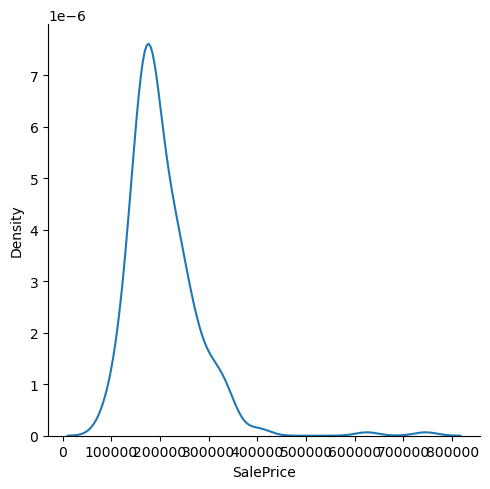

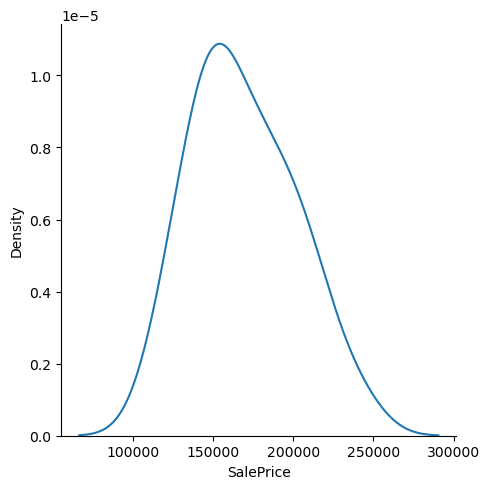

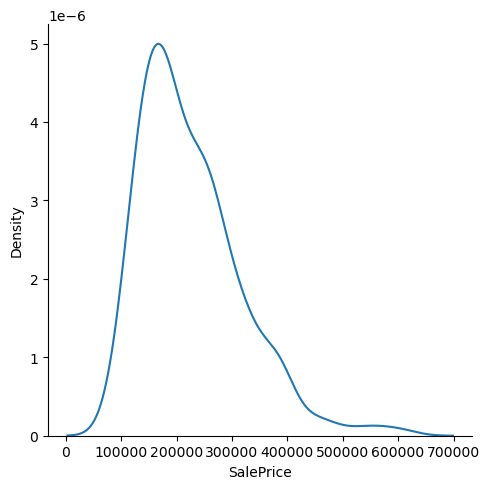

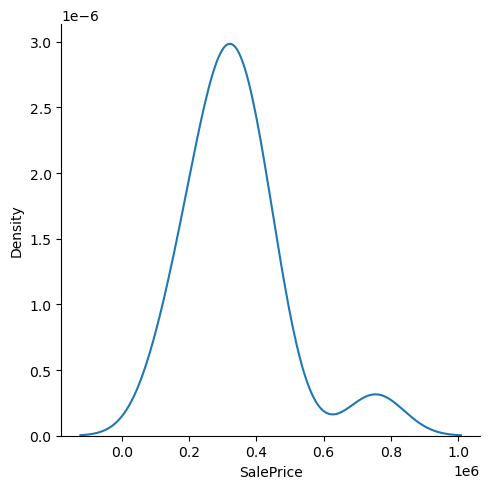

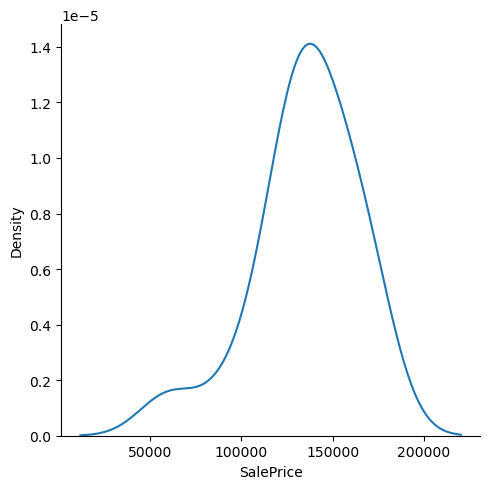

In [42]:
for category in X_train['FireplaceQu'].dropna().unique():
    sns.displot(X_train[X_train['FireplaceQu']==category]['SalePrice'],kind='kde',label=category)
    plt.show()

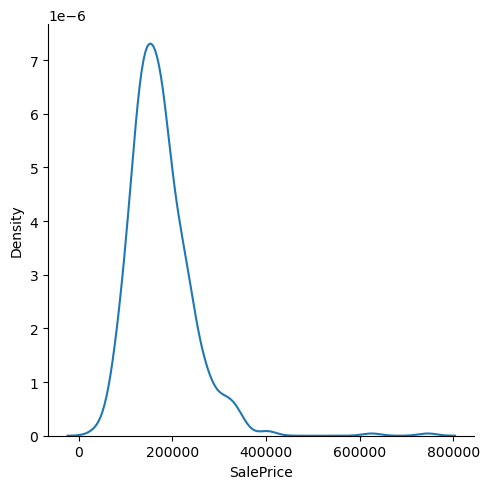

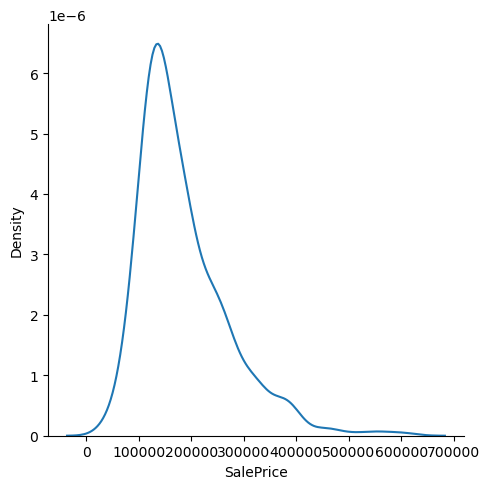

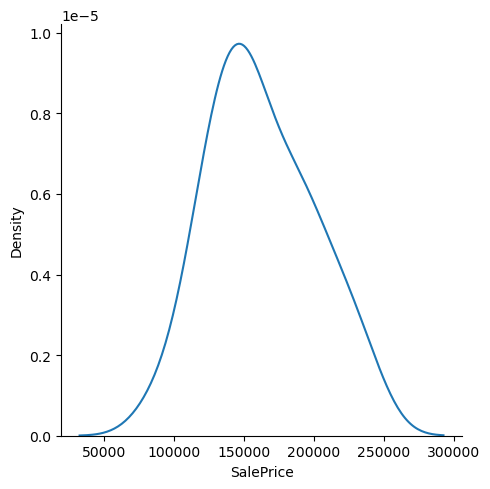

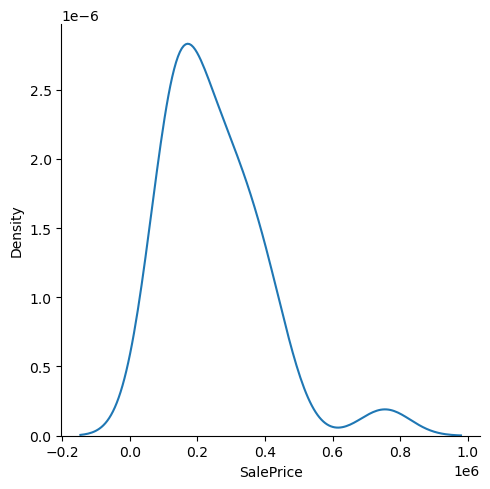

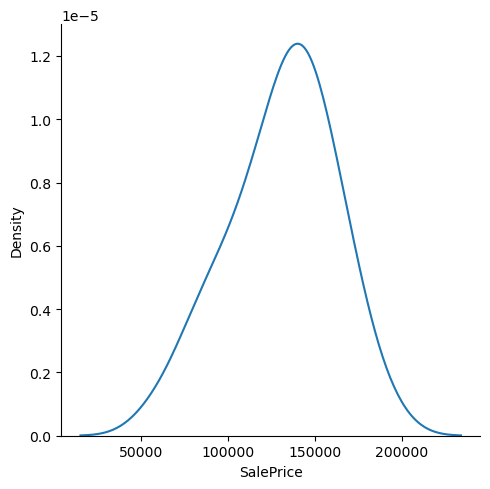

In [43]:
for category in X_train['FireplaceQu_imputed'].dropna().unique():
    sns.displot(X_train[X_train['FireplaceQu_imputed']==category]['SalePrice'],kind='kde',label=category)
    plt.show()